# 로봇개 기울기 센서(IMU) 신호 확인

`tools/servoInitPose/servoInitPose.ino` 펌웨어(`CAPS`에 `IMU1` 포함)와 함께 쓰는 노트북입니다. **이 노트북은 로봇을 움직이지 않습니다.** 센서 값만 읽습니다. 영점·축 설정을 저장하는 셀도 설정만 저장하고 서보는 움직이지 않습니다.

## 사용 전에
- USB 게이트웨이, Arduino 시리얼 모니터, 다른 노트북처럼 COM14를 쓰는 프로그램을 모두 닫으세요. 포트는 한 프로그램만 열 수 있습니다.
- 서보 전원은 꺼 두어도 됩니다. 센서는 USB 전원으로 동작합니다.
- 포트는 DTR/RTS를 끈 채로 열기 때문에 ESP32가 리셋되지 않습니다.

## 표시되는 값
| 값 | 뜻 |
|---|---|
| `ready` | 센서를 찾아 초기화했는지 (1 = 예) |
| `chip` / `who` / `addr` | 센서 칩 이름(MPU9250, MPU9255, MPU6500, MPU6050, ICM20948, 호환 칩이면 MPU_COMPATIBLE), 종류 코드, I2C 주소 |
| `valid` / `age` | 최근 0.2초 안에 쓸 수 있는 샘플이 있는지, 마지막 샘플이 몇 ms 전인지 |
| `ax` `ay` `az` | 센서 축별 가속도(g). 가만히 두면 합이 약 1 g |
| `x` `y` | 센서 X축·Y축의 기울기(도). 아직 로봇의 앞뒤·좌우 기울기와 같다는 보장은 없습니다 |
| `roll` `pitch` | 축 방향 설정(3번 항목) 후에만 표시. roll > 0 = 오른쪽이 낮음, pitch > 0 = 머리(앞)가 낮음 |

가속도로만 계산하므로 로봇을 흔들거나 걷는 중에는 값이 흔들리고 `valid`가 0이 될 수 있습니다. 1단계에서는 정상입니다.

In [6]:
import time

import serial
from IPython.display import clear_output

PORT = "COM14"
BAUD = 115200
esp = None

def open_serial_without_reset(port, baud):
    # Keep DTR/RTS deasserted so the ESP32 auto-reset circuit does not reboot the board.
    handle = serial.Serial()
    handle.port = port
    handle.baudrate = baud
    handle.timeout = 0.25
    handle.write_timeout = 2
    handle.dsrdtr = False
    handle.rtscts = False
    handle.dtr = False
    handle.rts = False
    handle.open()
    return handle

def send(command, prefix, timeout_s=2.0):
    """Send one command and return the reply line starting with prefix."""
    if esp is None or not esp.is_open:
        raise RuntimeError("먼저 '1. 연결하고 센서 확인' 셀을 실행하세요")
    esp.reset_input_buffer()
    esp.write((command + "\r\n").encode("ascii"))
    deadline = time.monotonic() + timeout_s
    while time.monotonic() < deadline:
        line = esp.readline().decode("ascii", errors="replace").strip()
        if not line or line.startswith("EVENT "):
            continue
        if line.startswith("ERR"):
            raise RuntimeError(line)
        if line.startswith(prefix):
            return line
    raise TimeoutError(f"{command} 응답이 없습니다")

def parse_fields(line):
    return dict(item.split("=", 1) for item in line.split()[1:] if "=" in item)

def number(text):
    try:
        return float(text)
    except (TypeError, ValueError):
        return None

def read_imu():
    return parse_fields(send("IMU", "IMU "))

def connect():
    global esp
    if esp is not None and esp.is_open:
        return "이미 연결되어 있습니다"
    esp = open_serial_without_reset(PORT, BAUD)
    try:
        deadline = time.monotonic() + 12
        next_hello = 0.0
        while True:
            if time.monotonic() >= deadline:
                raise TimeoutError("펌웨어 응답이 없습니다. 포트와 펌웨어를 확인하세요")
            if time.monotonic() >= next_hello:
                esp.write(b"HELLO\r\n")
                next_hello = time.monotonic() + 1
            if esp.readline().decode("ascii", errors="replace").strip() == "READY SERVO_POSE_V1":
                break
        caps = send("CAPS", "CAPS ").split()
        if "IMU1" not in caps:
            raise RuntimeError(f"IMU를 지원하지 않는 펌웨어입니다: {' '.join(caps)}. servoInitPose.ino를 다시 업로드하세요")
    except Exception:
        esp.close()
        esp = None
        raise
    return "연결됨"

def disconnect():
    global esp
    if esp is not None and esp.is_open:
        esp.close()
    esp = None
    return "연결을 해제했습니다"

## 1. 연결하고 센서 확인
아래 셀을 실행하면 연결 후 I2C 장치 목록과 센서 상태를 한 번 보여 줍니다.

In [7]:
print(connect())
print("I2C 장치:", send("I2C", "I2C").split()[1:])
imu = read_imu()
print(f"센서: ready={imu['ready']} chip={imu.get('chip', '?')} who={imu['who']} addr={imu['addr']} valid={imu['valid']} age={imu['age']}ms")
if imu["ready"] != "1":
    print("센서를 찾지 못했습니다. I2C 목록에 0x68 또는 0x69가 있는지, 배선(SDA 21, SCL 22, 3.3V, GND)을 확인하세요. 진단: send('I2CREAD 69 75', 'I2CREAD')")

연결됨
I2C 장치: ['0x40', '0x69']
센서: ready=1 chip=MPU_COMPATIBLE who=0x75 addr=0x68 valid=0 age=527852ms


## 2. 실시간 값 보기
로봇을 손으로 천천히 앞뒤·좌우로 기울이며 `x`, `y` 값이 어떻게 바뀌는지 보세요. 기본 20초 동안 0.2초마다 갱신합니다. 중간에 멈추려면 Jupyter의 정지(■) 버튼을 누르세요.

경과  13.1s / 20s   valid=0  age=553265ms
가속도 g : ax=     -  ay=     -  az=     -
센서 축 기울기(도): X=      -   Y=      -   (영점 저장=1)
로봇 기준(도): roll=      -  pitch=      -   (축 설정 roll=-Y, pitch=+X)
중지했습니다


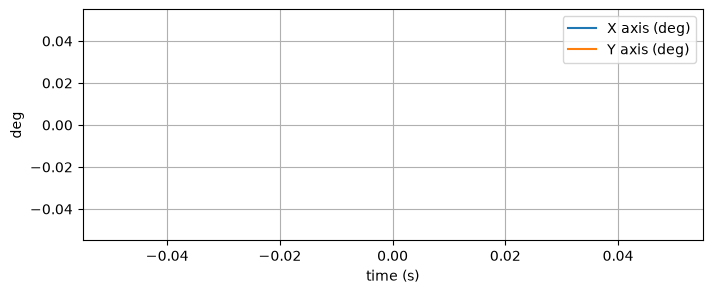

In [8]:
def monitor(seconds=20, interval_s=0.2):
    samples = []
    start = time.monotonic()
    try:
        while time.monotonic() - start < seconds:
            imu = read_imu()
            t = time.monotonic() - start
            samples.append((t, number(imu.get("x")), number(imu.get("y"))))
            clear_output(wait=True)
            print(f"경과 {t:5.1f}s / {seconds}s   valid={imu['valid']}  age={imu['age']}ms")
            print(f"가속도 g : ax={imu['ax']:>6}  ay={imu['ay']:>6}  az={imu['az']:>6}")
            print(f"센서 축 기울기(도): X={imu['x']:>7}   Y={imu['y']:>7}   (영점 저장={imu['zeroed']})")
            print(f"로봇 기준(도): roll={imu['roll']:>7}  pitch={imu['pitch']:>7}   "
                  f"(축 설정 roll={imu['rollmap']}, pitch={imu['pitchmap']})")
            time.sleep(interval_s)
    except KeyboardInterrupt:
        print("중지했습니다")
    return samples

samples = monitor(20)
try:
    import matplotlib.pyplot as plt
    ts = [s[0] for s in samples]
    plt.figure(figsize=(8, 3))
    plt.plot(ts, [s[1] for s in samples], label="X axis (deg)")
    plt.plot(ts, [s[2] for s in samples], label="Y axis (deg)")
    plt.xlabel("time (s)"); plt.ylabel("deg"); plt.grid(True); plt.legend(); plt.show()
except ImportError:
    print("matplotlib이 없어 그래프는 생략합니다")

## 3. (선택) 영점과 축 방향 설정
신호가 정상으로 보이면 아래 순서로 설정을 저장할 수 있습니다. 설정은 보드 플래시에 저장되고 재부팅 후에도 유지됩니다. 로봇이 활성화(ARM)되어 있거나 걷는 중이면 펌웨어가 거부합니다.

1. **영점:** 로봇을 평평한 바닥에 똑바로 세워 두고 `save_level()`을 실행합니다.
2. **앞뒤 축:** `record_tilt("nose_down")`을 실행한 뒤 3초 안에 로봇 **머리(앞쪽)를 아래로 약 15° 숙여** 2초간 유지합니다.
3. **좌우 축:** `record_tilt("right_down")`을 실행한 뒤 3초 안에 로봇 **오른쪽을 아래로 약 15° 기울여** 2초간 유지합니다.
4. `save_axis_map()`을 실행하면 두 기록으로 축과 부호를 정해 저장합니다. 그다음 '2. 실시간 값 보기' 셀을 다시 실행해 `roll`, `pitch`가 맞는 방향으로 바뀌는지 확인하세요.

잘못 저장했으면 `clear_axis_map()`으로 지울 수 있습니다.

In [3]:
tilts = {}

def save_level():
    send("IMUZERO", "OK IMUZERO")
    return "현재 자세를 수평(0°)으로 저장했습니다"

def record_tilt(name, wait_s=3, hold_s=2):
    print(f"{wait_s}초 안에 기울이세요...")
    time.sleep(wait_s)
    xs, ys = [], []
    end = time.monotonic() + hold_s
    while time.monotonic() < end:
        imu = read_imu()
        if imu["valid"] == "1":
            xs.append(float(imu["x"])); ys.append(float(imu["y"]))
        time.sleep(0.1)
    if len(xs) < 5:
        raise RuntimeError("유효한 샘플이 부족합니다. 천천히 기울여 다시 시도하세요")
    tilts[name] = (sum(xs) / len(xs), sum(ys) / len(ys))
    x, y = tilts[name]
    return f"{name}: X={x:.1f}°, Y={y:.1f}° 기록. 이제 원래 자세로 돌려 두세요"

def axis_for(record):
    x, y = record
    axis, value = ("X", x) if abs(x) >= abs(y) else ("Y", y)
    other = abs(y) if axis == "X" else abs(x)
    if abs(value) < 8:
        raise RuntimeError(f"기울기가 너무 작습니다 ({value:.1f}°). 약 15° 기울여 다시 기록하세요")
    if other > abs(value) * 0.5:
        print(f"주의: 두 축이 함께 크게 변했습니다 (X={x:.1f}, Y={y:.1f}). 한 방향으로만 기울였는지 확인하세요")
    return ("+" if value > 0 else "-") + axis

def save_axis_map():
    if "nose_down" not in tilts or "right_down" not in tilts:
        raise RuntimeError("nose_down과 right_down을 먼저 기록하세요")
    pitch = axis_for(tilts["nose_down"])   # pitch > 0 = nose lower
    roll = axis_for(tilts["right_down"])   # roll  > 0 = right side lower
    if pitch[1] == roll[1]:
        raise RuntimeError(f"두 기록이 같은 센서 축({roll[1]})을 가리킵니다. 다시 기록하세요")
    send(f"IMUMAP {roll} {pitch}", "OK IMUMAP")
    return f"저장했습니다: roll = {roll}, pitch = {pitch}"

def clear_axis_map():
    send("IMUMAP CLEAR", "OK IMUMAP")
    return "축 설정을 지웠습니다"

# 예시 (한 줄씩 실행):
# save_level()
# record_tilt("nose_down")
# record_tilt("right_down")
# save_axis_map()

In [4]:
save_level()                # 평평한 바닥에 똑바로 세운 상태에서

RuntimeError: ERR imu_not_valid

In [12]:
record_tilt("nose_down")    # 실행 후 3초 안에 머리(앞쪽)를 약 15° 숙이고 2초 유지

3초 안에 기울이세요...


'nose_down: X=14.8°, Y=9.0° 기록. 이제 원래 자세로 돌려 두세요'

In [13]:
record_tilt("right_down")   # 실행 후 3초 안에 오른쪽을 약 15° 낮추고 2초 유지

3초 안에 기울이세요...


'right_down: X=2.3°, Y=-11.4° 기록. 이제 원래 자세로 돌려 두세요'

In [14]:
save_axis_map()             # 결과: "roll = ..., pitch = ..."

주의: 두 축이 함께 크게 변했습니다 (X=14.8, Y=9.0). 한 방향으로만 기울였는지 확인하세요


'저장했습니다: roll = -Y, pitch = +X'

## 4. 연결 해제
다른 프로그램(게이트웨이, 보행 노트북)에서 COM14를 쓰려면 먼저 연결을 해제하세요.

In [9]:
print(disconnect())

연결을 해제했습니다
